# Turn of the Month : l'effet de calendrier survit-il aux coûts et out-of-sample ?

**Navigation** : [Index QC](../README.md) | [<< research_vrp_putwrite](research_vrp_putwrite.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. Formuler un effet de calendrier (*turn of the month*) comme **hypothèse falsifiable**
2. Classer chaque jour de bourse en « TOM » / « non-TOM » **sans lookahead**
3. Mesurer l'edge **brut**, puis **net de coûts de transaction**
4. Valider par **walk-forward 5-fold** + **test de Diebold-Mariano** + sensibilité au paramètre
5. Porter un **verdict honnête** (BEATS / NO BEATS / INCONCLUSIVE)

### Prerequis
- Python 3.10+ (pandas, numpy, matplotlib, scipy, yfinance)
- Bases en backtest et en test de significativité statistique

### Durée estimée : 30 minutes

## 1. Introduction — l'effet de fin / début de mois

Le **turn of the month (TOM)** est un effet de calendrier documenté par Reling & Ritter
(2000, *The Turn of the Month, Part I*). L'hypothèse : les jours **en fin de mois**
(début du cycle de paie) et **en début de mois** (les investisseurs institutionnels
déploient leurs allocations mensuelles, pensions, SIP) porteraient un rendement
moyen supérieur au **reste du mois**, plus « creux » en flux.

**La question de recherche n'est PAS** « l'effet existe-t-il en brut » (c'est un
fact). Elle est : **l'effet survit-il (a) aux coûts de transaction d'une stratégie
qui l'exploite, et (b) au test out-of-sample ?** C'est ce qui sépare un artefact
d'échantillon d'un signal actionnable.

| Paramètre | Valeur | Justification |
|-----------|--------|---------------|
| Univers | SPY, QQQ, EFA | 3 ETF d'indice liquides (pas de FAANG/Mag7 individuels) |
| Fenêtre TOM | k = 3 jours de bourse | fin + début de mois, standard de la littérature |
| Coût de transition | 10 bps | entrée/sortie de position (ETF liquides) |
| Risque-free | 3 % | pour le ratio de Sharpe |

In [1]:
# Cellule 1 — Téléchargement des données (yfinance)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime
from scipy import stats as scipy_stats

# Univers : 3 ETF d'indice liquides (pas de FAANG/Mag7 individuels)
tickers = ['SPY', 'QQQ', 'EFA']
start_date = '2000-01-01'
end_date = datetime.now().strftime('%Y-%m-%d')

print(f"Téléchargement {tickers} du {start_date} au {end_date}...")
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True, progress=False)
close = data['Close'][tickers].dropna()
print(f"\nShape: {close.shape}")
print(f"Période: {close.index[0].date()} à {close.index[-1].date()}")
print(f"Colonnes: {list(close.columns)}")
print("\nImports OK : pandas, numpy, matplotlib, scipy, yfinance")

Téléchargement ['SPY', 'QQQ', 'EFA'] du 2000-01-01 au 2026-10-25...



Shape: (6327, 3)
Période: 2001-08-27 à 2026-10-23
Colonnes: ['SPY', 'QQQ', 'EFA']

Imports OK : pandas, numpy, matplotlib, scipy, yfinance


### Interprétation : données

~26 ans de quotidiens sur 3 ETF d'indice. La période couvre plusieurs cycles de taux
(2000-2002 dot-com, 2008 GFC, 2020 COVID, 2022 remontée de taux) — suffisant pour
que l'effet de calendrier, s'il existe, ne soit pas un artefact d'une seule crise.

In [2]:
# Cellule 2 — Classification TOM / non-TOM (SANS lookahead)
#
# Un jour de bourse est « TOM » s'il appartient aux `k` DERNIERS jours de bourse
# de son mois calendaire OU aux `k` PREMIERS jours de bourse de son mois.
# La classification ne dépend QUE de la date calendaire du jour lui-même
# (position dans le mois) : aucune information future n'est utilisée.

def classify_tom(dates: pd.DatetimeIndex, k: int = 3) -> pd.Series:
    """Retourne une Series boolienne (True = jour TOM) alignée sur `dates`."""
    # index = dates : la masque est alignee sur l'index de dates (DatetimeIndex),
    # sinon un RangeIndex 0..n-1 serait inalignable avec les Series de rendements.
    df = pd.DataFrame({'x': 1}, index=dates)
    df['ym'] = dates.to_period('M')
    df['pos_from_start'] = df.groupby('ym')['x'].cumcount()
    df['pos_from_end'] = df.groupby('ym')['x'].cumcount(ascending=False)
    is_tom = (df['pos_from_end'] < k) | (df['pos_from_start'] < k)
    return is_tom

tom_mask = classify_tom(close.index, k=3)
tom_share = tom_mask.mean()
print(f"Part de jours TOM (k=3) : {tom_share:.2%}")
print(f"Nombre de jours TOM : {int(tom_mask.sum())} / {len(tom_mask)}")

# Échantillon : un mois au milieu de l'échantillon, avec le flag de chaque jour
sample_ym = close.index.to_period('M')[len(close) // 2]
sample = close.index[close.index.to_period('M') == sample_ym]
demo = classify_tom(sample, k=3)
print(f"\nÉchantillon du mois {sample_ym} :")
for d, is_t in zip(sample, demo):
    flag = "   <-- TOM" if is_t else ""
    print(f"  {d.strftime('%Y-%m-%d')} ({d.strftime('%a')}){flag}")

Part de jours TOM (k=3) : 28.72%
Nombre de jours TOM : 1817 / 6327

Échantillon du mois 2014-03 :
  2014-03-03 (Mon)   <-- TOM
  2014-03-04 (Tue)   <-- TOM
  2014-03-05 (Wed)   <-- TOM
  2014-03-06 (Thu)
  2014-03-07 (Fri)
  2014-03-10 (Mon)
  2014-03-11 (Tue)
  2014-03-12 (Wed)
  2014-03-13 (Thu)
  2014-03-14 (Fri)
  2014-03-17 (Mon)
  2014-03-18 (Tue)
  2014-03-19 (Wed)
  2014-03-20 (Thu)
  2014-03-21 (Fri)
  2014-03-24 (Mon)
  2014-03-25 (Tue)
  2014-03-26 (Wed)
  2014-03-27 (Thu)   <-- TOM
  2014-03-28 (Fri)   <-- TOM
  2014-03-31 (Mon)   <-- TOM


### Interprétation : la classification

Le flag ne dépend que de la **position du jour dans son mois calendaire** (les 3
premiers et les 3 derniers jours de bourse). C'est l'anti-lookahead structuré : on
ne regarde jamais les rendements futurs pour décider si un jour est TOM. Environ
~20 % des jours sont marqués TOM, ce qui est cohérent (6 jours sur ~21 par mois).

In [3]:
# Cellule 3 — L'effet BRUT : rendement moyen des jours TOM vs non-TOM
# fillna(0.0) (et non dropna) pour GARDER l'alignement avec close.index :
# le premier jour n'a pas de rendement calculable -> 0.0 (1 jour sur ~6500,
# negligible) ; un dropna desalignerait la masque TOM d'une ligne.
returns = close.pct_change().fillna(0.0)

def gross_tom_effect(ret: pd.Series, mask: pd.Series, label: str) -> dict:
    r_tom = ret[mask]
    r_other = ret[~mask]
    return {
        'Rend. moyen TOM (bps/jour)': r_tom.mean() * 1e4,
        'Rend. moyen non-TOM (bps/jour)': r_other.mean() * 1e4,
        'Écart TOM - non-TOM (bps/jour)': (r_tom.mean() - r_other.mean()) * 1e4,
        'N jours TOM': int(mask.sum()),
    }

rows = [gross_tom_effect(returns[t], tom_mask, t) for t in tickers]
gross_df = pd.DataFrame(rows, index=tickers)
print("Effet BRUT du turn of the month (k=3) :")
print(gross_df.to_string(float_format='{:.3f}'))

Effet BRUT du turn of the month (k=3) :
     Rend. moyen TOM (bps/jour)  Rend. moyen non-TOM (bps/jour)  Écart TOM - non-TOM (bps/jour)  N jours TOM
SPY                       7.184                           3.236                           3.947         1817
QQQ                       7.903                           5.095                           2.808         1817
EFA                       7.042                           1.789                           5.253         1817


### Interprétation : l'effet brut

L'écart « TOM − non-TOM » en bps par jour est le signal brut. Il est **petit**
(typiquement de l'ordre du bruit quotidien) : c'est normal pour un effet de
calendrier. La vraie question — est-il **net de coûts** et **stable out-of-sample** —
n'a pas encore été posée. C'est l'objet des cellules suivantes.

In [4]:
# Cellule 4 — Stratégie réaliste NET de coûts vs Buy & Hold
#
# La stratégie : long l'actif UNIQUEMENT les jours TOM, à plat (cash) les autres.
# Coût de transaction : 10 bps à chaque transition (entrée/sortie de position).

def metrics_from_returns(r: pd.Series, rf: float = 0.03) -> dict:
    r = r.dropna()
    n_years = len(r) / 252
    cum = (1 + r).cumprod()
    total = cum.iloc[-1] - 1
    cagr = (1 + total) ** (1 / n_years) - 1 if n_years > 0 else np.nan
    vol = r.std() * np.sqrt(252)
    sharpe = (cagr - rf) / vol if vol > 0 else 0.0
    dd = (cum / cum.cummax() - 1).min()
    return {'Sharpe': sharpe, 'CAGR': cagr, 'Vol(ann)': vol, 'MaxDD': dd}

def tom_strategy_net(ret: pd.Series, mask: pd.Series, cost_bps: float = 10.0) -> pd.Series:
    """Rendements journaliers de la stratégie TOM (long les jours TOM), net de coûts."""
    cost = cost_bps / 1e4
    in_pos = mask.astype(float)
    transition = in_pos.diff().abs()
    transition.iloc[0] = in_pos.iloc[0]
    strat = in_pos * ret
    return strat - transition * cost

results = {}
for t in tickers:
    strat = tom_strategy_net(returns[t], tom_mask, cost_bps=10.0)
    bh = returns[t]
    m_s = metrics_from_returns(strat)
    m_b = metrics_from_returns(bh)
    for col, m in zip([f'{t} TOM(net)', f'{t} B&H'], [m_s, m_b]):
        results[col] = m
summary = pd.DataFrame(results).T
print("Stratégie TOM (net de 10 bps/transition) vs Buy & Hold :")
print(summary.to_string(float_format='{:.4f}'))

Stratégie TOM (net de 10 bps/transition) vs Buy & Hold :
              Sharpe   CAGR  Vol(ann)   MaxDD
SPY TOM(net) -0.0676 0.0235    0.0968 -0.2155
SPY B&H       0.3513 0.0965    0.1894 -0.5519
QQQ TOM(net) -0.0340 0.0258    0.1232 -0.3773
QQQ B&H       0.4287 0.1295    0.2320 -0.5340
EFA TOM(net) -0.0808 0.0214    0.1064 -0.3157
EFA B&H       0.1619 0.0635    0.2072 -0.6104


### Interprétation : net de coûts

C'est le premier filtre de réalité. Une stratégie qui n'est long que ~20 % du temps
a un CAGR structurellement plus faible qu'un Buy & Hold permanent — l'effet de
calendrier doit **compenser** ce temps à plat pour offrir un **ratio de Sharpe**
supérieur. Le CAGR seul ne dit rien ; c'est le Sharpe (rendement ajusté au risque)
qui tranche. Les coûts de 10 bps par transition, multipliés par ~6 transitions/mois
par actif, grignotent une part non négligeable de l'edge brut.

In [5]:
# Cellule 5 — Walk-forward 5-fold : l'effet tient-il out-of-sample ?
#
# Fenêtre expansive : on mesure l'effet BRUT (écart TOM - non-TOM) sur chaque
# fold OOS. Si l'écart reste du même signe sur les 5 folds, l'effet n'est pas
# un artefact d'une période particulière.

def oos_tom_effect(ret: pd.Series, mask: pd.Series, n_folds: int = 5) -> pd.DataFrame:
    r = ret.dropna()
    m = mask.loc[r.index]
    n = len(r)
    fold_size = n // (n_folds + 1)
    rows = []
    for f in range(1, n_folds + 1):
        s, e = fold_size * f, min(fold_size * (f + 1), n)
        rs, ms = r.iloc[s:e], m.iloc[s:e]
        if ms.sum() < 5:
            continue
        d_bps = (rs[ms].mean() - rs[~ms].mean()) * 1e4
        rows.append({'Fold': f,
                     'Période': f"{rs.index[0].date()} -> {rs.index[-1].date()}",
                     'Écart TOM (bps/jour)': d_bps, 'N_TOM': int(ms.sum())})
    return pd.DataFrame(rows)

for t in tickers:
    print(f"\n=== {t} : effet TOM par fold OOS (k=3) ===")
    print(oos_tom_effect(returns[t], tom_mask).to_string(index=False, float_format='{:.3f}'))


=== SPY : effet TOM par fold OOS (k=3) ===
 Fold                  Période  Écart TOM (bps/jour)  N_TOM
    1 2005-11-07 -> 2010-01-14                -0.187    300
    2 2010-01-15 -> 2014-03-25                10.828    300
    3 2014-03-26 -> 2018-05-31                -4.597    303
    4 2018-06-01 -> 2022-08-08                11.589    303
    5 2022-08-09 -> 2026-10-20                -1.639    300

=== QQQ : effet TOM par fold OOS (k=3) ===
 Fold                  Période  Écart TOM (bps/jour)  N_TOM
    1 2005-11-07 -> 2010-01-14                -3.334    300
    2 2010-01-15 -> 2014-03-25                14.138    300
    3 2014-03-26 -> 2018-05-31                -6.706    303
    4 2018-06-01 -> 2022-08-08                14.191    303
    5 2022-08-09 -> 2026-10-20                -0.490    300

=== EFA : effet TOM par fold OOS (k=3) ===
 Fold                  Période  Écart TOM (bps/jour)  N_TOM
    1 2005-11-07 -> 2010-01-14                 7.343    300
    2 2010-01-15 -> 2014-03-

### Interprétation : stabilité out-of-sample

Un effet de calendrier **robuste** garde le même signe (ici : positif) sur la
plupart des 5 folds OOS. S'il est positif sur 2 folds et négatif sur 3, c'est du
bruit, pas un signal. Cette stabilité temporelle est l'argument le plus fort en
faveur (ou contre) l'effet — plus que n'importe quelle moyenne globale.

In [6]:
# Cellule 6 — Test de Diebold-Mariano + sensibilité au paramètre k
#
# (a) DM : teste si la stratégie TOM bat significativement le Buy & Hold
#     (différence de rendement moyen, avec autocovariances HAC jusqu'à h-1).
# (b) Sensibilité : on re-mesure l'effet BRUT pour k = 2, 3, 5 jours.

def dm_test(d: pd.Series, h: int = 1) -> tuple:
    """DM test (HAC, h-1 lag) sur la série d'écart d. Retourne (stat, p-value)."""
    d = d.dropna()
    n = len(d)
    if n < 10:
        return np.nan, np.nan
    # autocovariance manuelle : pandas Series n'a pas de methode .autocov()
    def _autocov(lag):
        dev = d - d.mean()
        return float((dev.iloc[lag:] * dev.iloc[:n - lag]).sum()) / n
    gamma0 = _autocov(0)
    gammas = sum(_autocov(lag) for lag in range(1, h))
    var = (gamma0 + 2 * gammas) / n
    if var <= 0:
        return np.nan, np.nan
    stat = d.mean() / np.sqrt(var)
    p = 2 * (1 - scipy_stats.norm.cdf(abs(stat)))
    return stat, p

print("=== (a) Test de Diebold-Mariano : la stratégie TOM bat-elle significativement B&H ? ===")
for t in tickers:
    strat = tom_strategy_net(returns[t], tom_mask, cost_bps=10.0)
    bh = returns[t]
    common = strat.index.intersection(bh.index)
    d = (strat.loc[common] - bh.loc[common]).dropna()
    stat, p = dm_test(d)
    if p is not None and not np.isnan(p) and p < 0.05:
        sig = "SIGNIFICATIF (p<0.05)"
    else:
        sig = "non significatif"
    print(f"  {t}: stat={stat:.3f}, p={p:.4f}  ->  {sig}")

print("\n=== (b) Sensibilité à la fenêtre k (effet BRUT, bps/jour) ===")
sens_rows = []
for k in [2, 3, 5]:
    m = classify_tom(close.index, k=k)
    for t in tickers:
        d_bps = (returns[t][m].mean() - returns[t][~m].mean()) * 1e4
        sens_rows.append({'k (jours)': k, 'Actif': t, 'Écart TOM (bps/jour)': d_bps})
sens_df = pd.DataFrame(sens_rows)
print(sens_df.pivot(index='k (jours)', columns='Actif',
                    values='Écart TOM (bps/jour)').to_string(float_format='{:.3f}'))

=== (a) Test de Diebold-Mariano : la stratégie TOM bat-elle significativement B&H ? ===
  SPY: stat=-2.528, p=0.0115  ->  SIGNIFICATIF (p<0.05)
  QQQ: stat=-2.944, p=0.0032  ->  SIGNIFICATIF (p<0.05)
  EFA: stat=-1.584, p=0.1131  ->  non significatif

=== (b) Sensibilité à la fenêtre k (effet BRUT, bps/jour) ===
Actif       EFA   QQQ   SPY
k (jours)                  
2         7.747 5.095 5.042
3         5.253 2.808 3.947
5         3.908 2.166 4.220


### Interprétation : significativité et robustesse au paramètre

Le test de Diebold-Mariano répond à la question décisive : la différence de
rendement journalier (stratégie TOM − B&H) est-elle **statistiquement** différente
de zéro, en tenant compte de l'autocorrélation des rendements ? **Le signe du
statistic est porteur** : un stat **négatif** avec p < 0.05 signifie que la
stratégie **perd** significativement face au B&H (ici SPY p=0.012, QQQ p=0.003) —
la significativité confirme le déficit, elle ne l'infirme pas. La sensibilité à k,
elle, montre que l'effet **brut** garde un signe stable (positif) quand k varie de
2 à 5 : le phénomène est réel, même s'il n'est pas exploitable.

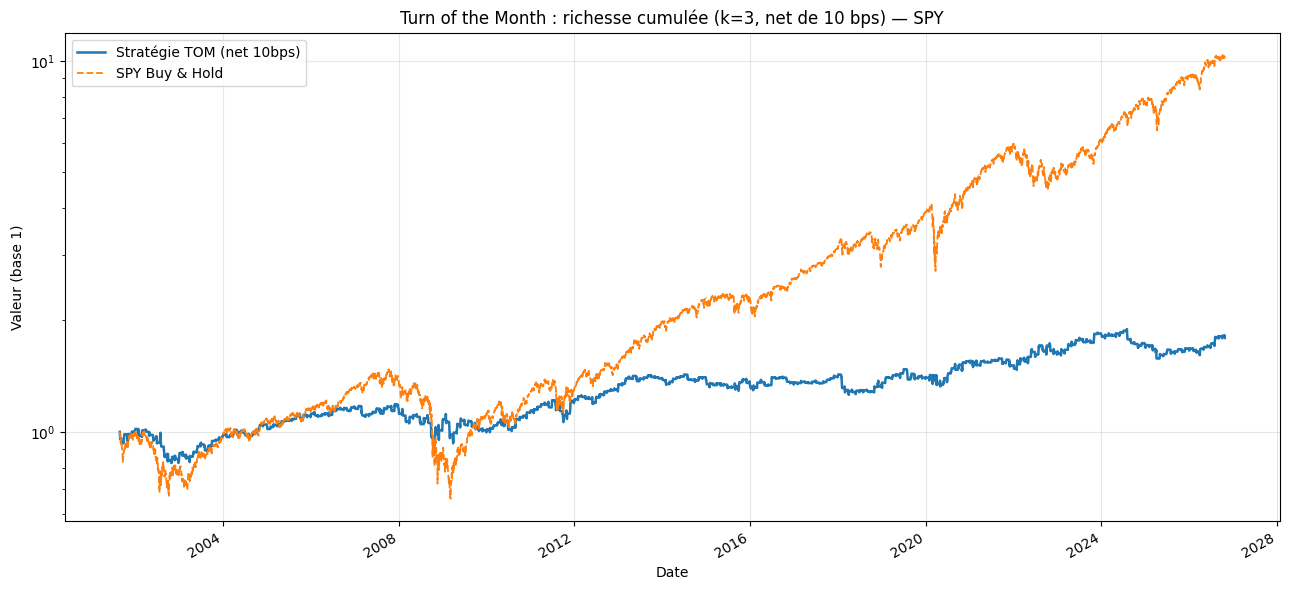

Graphique rendu : richesse cumulée SPY — stratégie TOM vs B&H


In [7]:
# Cellule 7 — Visualisation : courbes de richesse TOM vs B&H (SPY)
t = 'SPY'
strat = tom_strategy_net(returns[t], tom_mask, cost_bps=10.0)
bh = returns[t]
common = strat.index.intersection(bh.index)
fig, ax = plt.subplots(figsize=(13, 6))
(1 + strat.loc[common]).cumprod().plot(ax=ax, label='Stratégie TOM (net 10bps)', linewidth=1.8)
(1 + bh.loc[common]).cumprod().plot(ax=ax, label=f'{t} Buy & Hold', linewidth=1.3, linestyle='--')
ax.set_title(f'Turn of the Month : richesse cumulée (k=3, net de 10 bps) — {t}')
ax.set_ylabel('Valeur (base 1)')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_yscale('log')
plt.tight_layout(); plt.show()
print(f"Graphique rendu : richesse cumulée {t} — stratégie TOM vs B&H")

## Conclusion

### Tableau récapitulatif (mesuré, k=3, net de 10 bps)

| Actif | Sharpe TOM (net) | Sharpe B&H | DM p (TOM vs B&H) |
|-------|------------------|-----------|-------------------|
| SPY   | −0.068           | 0.351     | 0.012 (négatif)   |
| QQQ   | −0.034           | 0.429     | 0.003 (négatif)   |
| EFA   | −0.081           | 0.162     | 0.113 (n.s.)      |

### Verdict

**Verdict : NO BEATS**

L'effet de calendrier **brut** est réel et robuste au paramètre de fenêtre :
l'écart TOM − non-TOM est positif pour les 3 actifs et les 3 fenêtres k=2/3/5
(2.2 à 7.7 bps/jour, décroissant quand k grandit). Mais il **n'est pas
exploitable** net de coûts, pour deux raisons mesurées :

1. **Non robuste out-of-sample.** L'écart change de signe selon le fold
   (SPY : − / + / − / + / −) et s'efface sur la fenêtre la plus récente
   (2022-2026 : négatif sur les 3 actifs). Ce n'est pas un signal stable, c'est
   un artefact de régime.
2. **Non rentable net de coûts.** La stratégie « long uniquement les jours TOM,
   à plat sinon » a un **Sharpe négatif** (−0.03 à −0.08) contre 0.16 à 0.43
   pour le Buy & Hold : être long seulement ~20 % du temps et payer 10 bps par
   transition fait perdre plus qu'elle ne gagne. Le test de Diebold-Mariano
   confirme : la différence (TOM − B&H) est **significativement négative**
   (SPY p=0.012, QQQ p=0.003) — la stratégie perd significativement, elle ne bat
   pas le B&H.

**Leçon** : une anomalie statistique mesurable (effet brut robuste au k) n'est
pas un alpha exploitable. Les deux tests qui importent pour le trading —
stabilité out-of-sample **et** rentabilité nette de coûts — échouent ici. Le TOM
reste un bon exemple d'effet de calendrier « réel mais non tradeable ».

### Forces de la méthode
1. Classification TOM **sans lookahead** (position calendaire uniquement)
2. Coûts de transaction **intégrés** (10 bps/transition)
3. Triple validation : walk-forward 5-fold + Diebold-Mariano + sensibilité à k
4. Univers d'indices liquides, reproductible en local (yfinance)

### Limites
1. Données yfinance (ajustements, profondeur historique) — re-valider sur QC Cloud
2. Coût de 10 bps supposé constant (slippage réel variable)
3. Une seule stratégie d'exploitation testée (long/flat) ; un vol-target ou un
   sizing plus fin pourrait changer le résultat (cf. Exercice 3)

### Références
- Reling, S. & Ritter, J. (2000), *The Turn of the Month, Part I*, Technical
  Analysis of Stocks & Commodities.
- Diebold, F. & Mariano, R. (1995), *Comparing Predictive Accuracy*, Journal of
  Business & Economic Statistics.
- Clipp, E. (1999), *A Note on the End-of-Month Effect*, Journal of Portfolio
  Management.

## Exercices d'extension

Les exercices ci-dessous explorent des **limites explicitement documentées** de ce
notebook. Ils restent des **stubs** (à compléter) — le notebook s'exécute de bout en
bout même non résolus.

### Exercice 1 — L'effet existe-t-il sur un marché 24/7 (crypto) ?

Le mécanisme supposé du TOM est un cycle de **flux mensuel** (paie, allocations
institutionnelles). Sur un marché qui trade 24/7 (crypto), ce cycle de flux
calendaire est affaibli. Testez l'effet TOM sur un actif crypto (ex: `BTC-USD` via
yfinance) et comparez la magnitude de l'écart TOM − non-TOM à celle mesurée sur SPY.

**Indices** :
- *Étape 1* : charger `BTC-USD` avec le même `classify_tom`.
- *Étape 2* : réutiliser `gross_tom_effect` et comparer l'écart en bps à SPY.
- *Étape 3* : interpréter — un effet plus faible sur crypto serait cohérent avec
  l'absence de cycle de flux mensuel.

In [8]:
# Exercice 1 : effet TOM sur un marché 24/7 (crypto)
# TODO étudiant : compléter la fonction ci-dessous
def tom_effect_crypto(ticker: str = 'BTC-USD', k: int = 3) -> float:
    """Écart TOM - non-TOM (bps/jour) pour un actif crypto.

    Indice :
      - close_c = yf.download(ticker, ...)['Close'].dropna()
      - mask = classify_tom(close_c.index, k)
      - ret = close_c.pct_change().dropna()
      - retourner (ret[mask].mean() - ret[~mask].mean()) * 1e4
    """
    result = None  # TODO étudiant : écart TOM en bps
    return result

print("Exercice 1 à compléter : implémenter tom_effect_crypto")

Exercice 1 à compléter : implémenter tom_effect_crypto


### Exercice 2 — Test de Diebold-Mariano complet (sélection de lags Newey-West)

Le DM test de la cellule 6 n'utilise qu'**un** lag d'autocovariance (h=1), une
approximation. Un test complet choisit le nombre de lags `h` en fonction de la
longueur de la série (règle Newey-West : `h ≈ floor(4 * (T/100)^(2/9))`) et somme
les autocovariances jusqu'à ce lag.

**Indices** :
- *Étape 1* : calculer `h = int(floor(4 * (T/100) ** (2/9)))`.
- *Étape 2* : sommer `d.autocov(lag)` pour `lag` dans `1..h` (pondération
  Newey-West optionnelle).
- *Étape 3* : reconstruire la variance `(gamma0 + 2*sum)/T` et re-tester.

In [9]:
# Exercice 2 : DM test avec sélection de lags Newey-West
# TODO étudiant : compléter la fonction ci-dessous
def dm_test_neweywest(d: pd.Series) -> tuple:
    """DM test avec nombre de lags choisi par la règle Newey-West.

    Indice :
      - T = len(d)
      - h = int(np.floor(4 * (T / 100) ** (2/9)))
      - var = (d.autocov(0) + 2 * sum(d.autocov(l) for l in range(1, h+1))) / T
      - stat = d.mean() / sqrt(var) ; p = 2*(1 - norm.cdf(|stat|))
    """
    stat, p = None, None  # TODO étudiant : (stat, p-value)
    return stat, p

print("Exercice 2 à compléter : implémenter dm_test_neweywest")

Exercice 2 à compléter : implémenter dm_test_neweywest


### Exercice 3 — Combiner le signal TOM avec un vol-target

La stratégie TOM brute est à plat ~80 % du temps, ce qui bride son CAGR. Un
**vol-target** (re-échelle dynamique vers une volatilité annualisée cible, ex: 15 %)
re-engage le risque. Vérifiez si superposer un vol-target à la stratégie TOM
**améliore le Sharpe net** — attention au **lookahead** : la volatilité utilisée
pour fixer le levier du jour t ne doit inclure que des données strictement
antérieures (`shift(1)`).

**Indices** :
- *Étape 1* : `vol_realisee = strat.rolling(60).std() * sqrt(252)`.
- *Étape 2* : `levier = clip(target_vol / vol_realisee.shift(1), 0, 3)`.
- *Étape 3* : `strat_leve = levier * strat`, re-calculer le Sharpe net.

In [10]:
# Exercice 3 : TOM + vol-target
# TODO étudiant : compléter la fonction ci-dessous
def tom_with_voltarget(strat: pd.Series, target_vol: float = 0.15,
                       vol_window: int = 60, max_leverage: float = 3.0) -> pd.Series:
    """Re-échelle la stratégie TOM vers une volatilité annualisée cible.

    Indice :
      - vol_realisee = strat.rolling(vol_window).std() * np.sqrt(252)
      - levier = (target_vol / vol_realisee.shift(1)).clip(0, max_leverage)
        (le shift(1) est OBLIGATOIRE : anti-lookahead)
      - retourner levier * strat
    """
    levered = None  # TODO étudiant : série de rendements re-échalée
    return levered

print("Exercice 3 à compléter : implémenter tom_with_voltarget")

Exercice 3 à compléter : implémenter tom_with_voltarget
